### shapely 2: Lagebeziehungen, Schnittpunkte und Abstände - Übungen

In diesem Notebook geht es um die **Lage** von Figuren zueinander: Liegt ein Punkt in einem Vieleck? Schneiden sich zwei Strecken, und wo?
Wie weit ist ein Punkt von einer Strecke entfernt, und wo ist der Lotfußpunkt? Wie liegen Kreis und Gerade zueinander?

Die Reihe hat vier Notebooks:

1. Grundlagen: Geometrien erstellen, messen und zeichnen
2. **Lagebeziehungen** (dieses Notebook)
3. Mengen und Konstruktionen: Schnitt und Vereinigung, Abstandsbereiche, Hüllen, Voronoi-Diagramme
4. Abbildungen und Anwendungen: Verschieben, Drehen, Spiegeln, Strecken; Flächen unter Graphen; Monte-Carlo

Wie im ersten Notebook werden Ergebnisse gerundet ausgegeben (`shapely.to_wkt(g, rounding_precision=2)`, `round()`).

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Wenn etwas vorgegeben ist, steht es schon in der Codezelle.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ gibt es keine Lösung zum Aufklappen: Dort führst du einfach die Zelle aus und vergleichst.

## 1. Lagebeziehungen prüfen

#### Prädikate

Methoden, die `True` oder `False` zurückgeben, heißen **Prädikate**. Jede Figur hat ein **Inneres** und einen **Rand**
(bei einem Vieleck die Randlinie, bei einer Strecke die beiden Endpunkte).

| Methode | `True`, wenn ... |
|---|---|
| `a.intersects(b)` | a und b mindestens einen Punkt gemeinsam haben |
| `a.disjoint(b)` | a und b **keinen** Punkt gemeinsam haben |
| `a.contains(b)` | b ganz in a liegt und mindestens einen Punkt im **Inneren** von a hat |
| `a.within(b)` | a ganz in b liegt (umgekehrt zu `contains`) |
| `a.covers(b)` | kein Punkt von b außerhalb von a liegt (auch auf dem Rand erlaubt) |
| `a.touches(b)` | a und b sich nur am **Rand** berühren |
| `a.crosses(b)` | sich zwei Linien kreuzen (oder eine Linie durch ein Vieleck geht) |
| `a.equals(b)` | a und b dieselbe Punktmenge sind (auch bei anderer Eckenreihenfolge) |

In [ ]:
from shapely import Point, Polygon

q = Polygon([(0, 0), (4, 0), (4, 4), (0, 4)])
innen = Point(1, 2)
rand = Point(4, 2)
aussen = Point(6, 1)
print(q.contains(innen), q.contains(rand), q.contains(aussen))
print(q.covers(rand), q.touches(rand), q.intersects(rand))
print(innen.within(q), q.disjoint(aussen))

#### Vielecke und Linien

Zwei Vielecke, die nur eine Seite gemeinsam haben, **berühren** sich (`touches`). Überlappen sie, schneiden sie sich (`intersects`),
berühren sich aber nicht. `equals` vergleicht die Punktmengen, nicht die Liste der Ecken.

In [ ]:
from shapely import LineString, Polygon

a = Polygon([(0, 0), (2, 0), (2, 2), (0, 2)])
b = Polygon([(2, 0), (4, 0), (4, 2), (2, 2)])
c = Polygon([(1, 1), (3, 1), (3, 3), (1, 3)])
print(a.touches(b), a.intersects(b))
print(a.touches(c), a.intersects(c))
print(a.equals(Polygon([(2, 2), (0, 2), (0, 0), (2, 0)])))
print(LineString([(0, 0), (2, 2)]).crosses(LineString([(0, 2), (2, 0)])))

#### Aufgabe 1.1

Gib für die Punkte P(2|3), Q(6|3), R(7|1) aus, ob das Quadrat `q` sie enthält (`contains`).

**Erwartete Ausgabe:**
```
True
False
False
```

In [ ]:
from shapely import Point, Polygon

q = Polygon([(0, 0), (6, 0), (6, 6), (0, 6)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Point, Polygon

q = Polygon([(0, 0), (6, 0), (6, 6), (0, 6)])
for p in [Point(2, 3), Point(6, 3), Point(7, 1)]:
    print(q.contains(p))
```

</details>

#### Aufgabe 1.2

Gib für dieselben Punkte P(2|3), Q(6|3), R(7|1) aus, ob `q` sie überdeckt (`covers`) und ob sie den Rand berühren (`touches`), in der Form `True False`.

**Erwartete Ausgabe:**
```
True False
True True
False False
```

In [ ]:
from shapely import Point, Polygon

q = Polygon([(0, 0), (6, 0), (6, 6), (0, 6)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Point, Polygon

q = Polygon([(0, 0), (6, 0), (6, 6), (0, 6)])
for p in [Point(2, 3), Point(6, 3), Point(7, 1)]:
    print(q.covers(p), q.touches(p))
```

</details>

#### Aufgabe 1.3

Gib für jedes Rechteck in `rechtecke` aus, ob es `q` überlappt (`intersects`), ob es `q` nur berührt (`touches`) und ob es ganz in `q` liegt (`within`).

**Erwartete Ausgabe:**
```
True False True
True True False
True False False
False False False
```

In [ ]:
from shapely import Point, Polygon

q = Polygon([(0, 0), (6, 0), (6, 6), (0, 6)])
rechtecke = [Polygon([(1, 1), (3, 1), (3, 2), (1, 2)]), Polygon([(6, 0), (8, 0), (8, 3), (6, 3)]),
             Polygon([(5, 5), (8, 5), (8, 8), (5, 8)]), Polygon([(7, 7), (9, 7), (9, 9), (7, 9)])]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Point, Polygon

q = Polygon([(0, 0), (6, 0), (6, 6), (0, 6)])
rechtecke = [Polygon([(1, 1), (3, 1), (3, 2), (1, 2)]), Polygon([(6, 0), (8, 0), (8, 3), (6, 3)]),
             Polygon([(5, 5), (8, 5), (8, 8), (5, 8)]), Polygon([(7, 7), (9, 7), (9, 9), (7, 9)])]
for r in rechtecke:
    print(r.intersects(q), r.touches(q), r.within(q))
```

</details>

#### Aufgabe 1.4

Prüfe mit `equals()`, ob die beiden Dreiecke `d1` und `d2` gleich sind, und dann `d1` und `d3`. Vergleiche das mit `==`, das bei shapely nur gleiche Eckenlisten erkennt.

**Erwartete Ausgabe:**
```
True False
False False
```

In [ ]:
from shapely import Polygon

d1 = Polygon([(0, 0), (4, 0), (0, 3)])
d2 = Polygon([(4, 0), (0, 3), (0, 0)])
d3 = Polygon([(0, 0), (4, 0), (0, 4)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Polygon

d1 = Polygon([(0, 0), (4, 0), (0, 3)])
d2 = Polygon([(4, 0), (0, 3), (0, 0)])
d3 = Polygon([(0, 0), (4, 0), (0, 4)])
print(d1.equals(d2), d1 == d2)
print(d1.equals(d3), d1 == d3)
```

</details>

#### Aufgabe 1.5

Gib für jedes Paar von Strecken in `paare` aus, ob sie sich kreuzen (`crosses`), berühren (`touches`) oder überhaupt einen gemeinsamen Punkt haben (`intersects`).

**Erwartete Ausgabe:**
```
True False True
False True True
False False False
```

In [ ]:
from shapely import LineString

paare = [(LineString([(0, 0), (4, 4)]), LineString([(0, 4), (4, 0)])),
         (LineString([(0, 0), (4, 0)]), LineString([(4, 0), (4, 3)])),
         (LineString([(0, 0), (4, 0)]), LineString([(0, 1), (4, 1)]))]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import LineString

paare = [(LineString([(0, 0), (4, 4)]), LineString([(0, 4), (4, 0)])),
         (LineString([(0, 0), (4, 0)]), LineString([(4, 0), (4, 3)])),
         (LineString([(0, 0), (4, 0)]), LineString([(0, 1), (4, 1)]))]
for a, b in paare:
    print(a.crosses(b), a.touches(b), a.intersects(b))
```

</details>

#### Aufgabe 1.6

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
from shapely import Point, Polygon

d = Polygon([(0, 0), (4, 0), (0, 4)])
print(d.contains(Point(1, 1)), d.contains(Point(2, 2)), d.covers(Point(2, 2)))
print(d.contains(Point(3, 3)))
```

In [ ]:
from shapely import Point, Polygon

d = Polygon([(0, 0), (4, 0), (0, 4)])
print(d.contains(Point(1, 1)), d.contains(Point(2, 2)), d.covers(Point(2, 2)))
print(d.contains(Point(3, 3)))

#### Aufgabe 1.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
from shapely import Polygon

a = Polygon([(0, 0), (4, 0), (4, 4), (0, 4)])
b = Polygon([(1, 1), (2, 1), (2, 2), (1, 2)])
print(a.contains(b), b.within(a), b.contains(a))
print(a.intersects(b), a.touches(b), a.disjoint(b))
```

In [ ]:
from shapely import Polygon

a = Polygon([(0, 0), (4, 0), (4, 4), (0, 4)])
b = Polygon([(1, 1), (2, 1), (2, 2), (1, 2)])
print(a.contains(b), b.within(a), b.contains(a))
print(a.intersects(b), a.touches(b), a.disjoint(b))

## 2. Punkt im Vieleck

#### Viele Punkte prüfen

Mit einer Schleife prüft man viele Punkte. Ob ein Punkt auf dem Rand dazugehören soll, entscheidet man selbst:
mit `covers` (Rand gehört dazu) oder `contains` (Rand gehört nicht dazu).

In [ ]:
from shapely import Point, Polygon

spielfeld = Polygon([(0, 0), (10, 0), (10, 6), (0, 6)])
treffer = [(3, 2), (10, 4), (11, 1), (5, 6), (8, 5)]
drin = 0
for x, y in treffer:
    if spielfeld.covers(Point(x, y)):
        drin += 1
print(drin)

#### Aufgabe 2.1

Ein Ball ist **im Aus**, wenn er nicht auf dem Spielfeld liegt; die Linie gehört zum Feld. Gib für jede Position in `baelle` `drin` oder `aus` aus.

**Erwartete Ausgabe:**
```
drin
drin
aus
aus
drin
```

In [ ]:
from shapely import Point, Polygon

feld = Polygon([(0, 0), (105, 0), (105, 68), (0, 68)])
baelle = [(50, 30), (105, 10), (106, 10), (-1, 68), (0, 68)]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Point, Polygon

feld = Polygon([(0, 0), (105, 0), (105, 68), (0, 68)])
baelle = [(50, 30), (105, 10), (106, 10), (-1, 68), (0, 68)]
for x, y in baelle:
    if feld.covers(Point(x, y)):
        print('drin')
    else:
        print('aus')
```

</details>

#### Aufgabe 2.2

Gib die Namen aller Häuser aus, die im Gebiet `gebiet` liegen (ohne Rand).

**Erwartete Ausgabe:**
```
Müller
Weber
Rossi
```

In [ ]:
from shapely import Point, Polygon

gebiet = Polygon([(0, 0), (8, 0), (10, 5), (4, 9), (-2, 5)])
haeuser = {'Müller': (3, 3), 'Kaya': (9, 7), 'Weber': (-1, 4), 'Nowak': (8, 0), 'Rossi': (5, 7)}
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Point, Polygon

gebiet = Polygon([(0, 0), (8, 0), (10, 5), (4, 9), (-2, 5)])
haeuser = {'Müller': (3, 3), 'Kaya': (9, 7), 'Weber': (-1, 4), 'Nowak': (8, 0), 'Rossi': (5, 7)}
for name, (x, y) in haeuser.items():
    if gebiet.contains(Point(x, y)):
        print(name)
```

</details>

#### Aufgabe 2.3

Zähle, wie viele Gitterpunkte (ganzzahlige x und y von −5 bis 5) im Dreieck `d` liegen (ohne Rand) und wie viele auf dem Rand (mit `touches`).

**Erwartete Ausgabe:**
```
25 7
```

In [ ]:
from shapely import Point, Polygon

d = Polygon([(-4, -3), (5, -1), (0, 4)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Point, Polygon

d = Polygon([(-4, -3), (5, -1), (0, 4)])
innen = 0
rand = 0
for x in range(-5, 6):
    for y in range(-5, 6):
        p = Point(x, y)
        if d.contains(p):
            innen += 1
        elif d.touches(p):
            rand += 1
print(innen, rand)
```

</details>

#### Aufgabe 2.4

Zeichne das Gebiet `gebiet` (Füllung `'lightgray'`) und alle Punkte aus `punkte`: Punkte im Gebiet grün (`'green'`), die anderen rot (`'red'`).
Achsen gleich skaliert, Bildgröße 4 × 4.

**Erwartete Ausgabe:**

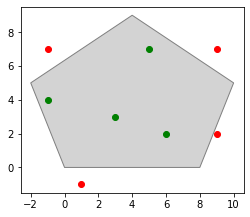

In [ ]:
import matplotlib.pyplot as plt
from shapely import Point, Polygon
from shapely.plotting import plot_points, plot_polygon

gebiet = Polygon([(0, 0), (8, 0), (10, 5), (4, 9), (-2, 5)])
punkte = [(3, 3), (9, 7), (-1, 4), (5, 7), (1, -1), (6, 2), (-1, 7), (9, 2)]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
from shapely import Point, Polygon
from shapely.plotting import plot_points, plot_polygon

gebiet = Polygon([(0, 0), (8, 0), (10, 5), (4, 9), (-2, 5)])
punkte = [(3, 3), (9, 7), (-1, 4), (5, 7), (1, -1), (6, 2), (-1, 7), (9, 2)]
fig, ax = plt.subplots(figsize=(4, 4))
plot_polygon(gebiet, ax=ax, facecolor='lightgray', edgecolor='gray', add_points=False)
for x, y in punkte:
    p = Point(x, y)
    if gebiet.contains(p):
        plot_points(p, ax=ax, color='green')
    else:
        plot_points(p, ax=ax, color='red')
ax.set_aspect('equal')
plt.show()
```

</details>

#### Aufgabe 2.5

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
from shapely import Point, Polygon

r = Polygon([(0, 0), (3, 0), (3, 2), (0, 2)])
anzahl = 0
for x in range(4):
    if r.contains(Point(x, 1)):
        anzahl += 1
print(anzahl)
```

In [ ]:
from shapely import Point, Polygon

r = Polygon([(0, 0), (3, 0), (3, 2), (0, 2)])
anzahl = 0
for x in range(4):
    if r.contains(Point(x, 1)):
        anzahl += 1
print(anzahl)

## 3. Schnittpunkte von Strecken und Geraden

#### `intersection()`

`a.intersection(b)` gibt die **gemeinsamen Punkte** zurück, als neue Geometrie. Bei zwei Strecken kann das sein:

| Ergebnis | `geom_type` | bedeutet |
|---|---|---|
| ein Punkt | `'Point'` | die Strecken schneiden sich |
| leer | `'LineString'` mit `is_empty == True` | kein gemeinsamer Punkt |
| eine Strecke | `'LineString'` | die Strecken liegen teilweise aufeinander |

Bei einem Streckenzug können es auch mehrere Punkte sein (`'MultiPoint'`). `geom_type` ist der Name des Typs, `is_empty` prüft, ob das Ergebnis leer ist.

In [ ]:
import shapely
from shapely import LineString

a = LineString([(0, 0), (4, 2)])
b = LineString([(0, 3), (3, 0)])
s = a.intersection(b)
print(s.geom_type, shapely.to_wkt(s, rounding_precision=2))
print(a.intersection(LineString([(5, 0), (5, 5)])).is_empty)
print(LineString([(0, 0), (4, 0)]).intersection(LineString([(2, 0), (6, 0)])))

#### Geraden

shapely kennt nur Strecken, keine unendlich langen Geraden. Eine Gerade y = mx + c stellt man durch eine **lange Strecke** dar, zum Beispiel von x = −100 bis x = 100.
Solange der Schnittpunkt in diesem Bereich liegt, findet shapely ihn.

In [ ]:
import shapely
from shapely import LineString

def gerade(m, c):
    return LineString([(-100, m * -100 + c), (100, m * 100 + c)])

s = gerade(2, -1).intersection(gerade(-0.5, 4))
print(shapely.to_wkt(s, rounding_precision=2))

#### Aufgabe 3.1

Gib den Schnittpunkt der Strecken von (0|0) nach (6|3) und von (0|4) nach (4|0) gerundet aus.

**Erwartete Ausgabe:**
```
POINT (2.67 1.33)
```

In [ ]:
import shapely
from shapely import LineString
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import LineString
s = LineString([(0, 0), (6, 3)]).intersection(LineString([(0, 4), (4, 0)]))
print(shapely.to_wkt(s, rounding_precision=2))
```

</details>

#### Aufgabe 3.2

Gib für jedes Paar in `paare` den Typ des Schnitts aus oder `kein Schnitt`, wenn er leer ist, in der Form `Point` / `LineString` / `kein Schnitt`.

**Erwartete Ausgabe:**
```
Point
kein Schnitt
LineString
kein Schnitt
```

In [ ]:
from shapely import LineString

paare = [(LineString([(0, 0), (4, 4)]), LineString([(0, 4), (4, 0)])),
         (LineString([(0, 0), (2, 2)]), LineString([(3, 0), (5, 2)])),
         (LineString([(0, 0), (4, 0)]), LineString([(1, 0), (6, 0)])),
         (LineString([(0, 0), (2, 0)]), LineString([(3, -1), (3, 1)]))]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import LineString

paare = [(LineString([(0, 0), (4, 4)]), LineString([(0, 4), (4, 0)])),
         (LineString([(0, 0), (2, 2)]), LineString([(3, 0), (5, 2)])),
         (LineString([(0, 0), (4, 0)]), LineString([(1, 0), (6, 0)])),
         (LineString([(0, 0), (2, 0)]), LineString([(3, -1), (3, 1)]))]
for a, b in paare:
    s = a.intersection(b)
    if s.is_empty:
        print('kein Schnitt')
    else:
        print(s.geom_type)
```

</details>

#### Aufgabe 3.3

Gib den Schnittpunkt der Geraden y = 3x − 2 und y = −x + 6 gerundet aus. Verwende die Funktion `gerade()` aus dem Beispiel.

**Erwartete Ausgabe:**
```
POINT (2 4)
```

In [ ]:
import shapely
from shapely import LineString

def gerade(m, c):
    return LineString([(-100, m * -100 + c), (100, m * 100 + c)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import LineString

def gerade(m, c):
    return LineString([(-100, m * -100 + c), (100, m * 100 + c)])

s = gerade(3, -2).intersection(gerade(-1, 6))
print(shapely.to_wkt(s, rounding_precision=2))
```

</details>

#### Aufgabe 3.4

Berechne den Schnittpunkt zweier Geraden y = m₁x + c₁ und y = m₂x + c₂ selbst durch Gleichsetzen: x = (c₂ − c₁)/(m₁ − m₂). Schreibe eine Funktion `schnitt(m1, c1, m2, c2)`,
die den Schnittpunkt als Tupel (auf 4 Stellen gerundet) oder `None` bei parallelen Geraden zurückgibt. Vergleiche für die Paare in `tests` mit shapely (gerundet auf 4 Stellen, oder `leer`).

**Erwartete Ausgabe:**
```
(2.0, 3.0) POINT (2 3)
None leer
(4.0, 2.0) POINT (4 2)
```

In [ ]:
import shapely
from shapely import LineString

def gerade(m, c):
    return LineString([(-100, m * -100 + c), (100, m * 100 + c)])

tests = [(2, -1, -0.5, 4), (1, 0, 1, 3), (0.25, 1, -3, 14)]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import LineString

def gerade(m, c):
    return LineString([(-100, m * -100 + c), (100, m * 100 + c)])

tests = [(2, -1, -0.5, 4), (1, 0, 1, 3), (0.25, 1, -3, 14)]

def schnitt(m1, c1, m2, c2):
    if m1 == m2:
        return None
    x = (c2 - c1) / (m1 - m2)
    return (round(x, 4), round(m1 * x + c1, 4))

for m1, c1, m2, c2 in tests:
    s = gerade(m1, c1).intersection(gerade(m2, c2))
    if s.is_empty:
        print(schnitt(m1, c1, m2, c2), 'leer')
    else:
        print(schnitt(m1, c1, m2, c2), shapely.to_wkt(s, rounding_precision=4))
```

</details>

#### Mehrere Schnittpunkte sortiert ausgeben

In welcher **Reihenfolge** die Punkte eines `MultiPoint`-Ergebnisses stehen, ist nicht festgelegt; sie kann sich von Version zu Version unterscheiden.
Damit man Ergebnisse vergleichen kann, macht man daraus eine Liste gerundeter Tupel und sortiert sie (nach x, bei gleichem x nach y).

In [ ]:
from shapely import LineString

s = LineString([(0, 0), (2, 4), (4, 0)]).intersection(LineString([(0, 1), (4, 1)]))
punkte = []
for p in s.geoms:
    punkte.append((round(p.x, 2), round(p.y, 2)))
print(sorted(punkte))

#### Aufgabe 3.5

Ein Wanderweg (Streckenzug `weg`) überquert mehrmals den Bach (Strecke `bach`). Gib die Anzahl der Übergänge aus und die Übergänge als sortierte Liste gerundeter Tupel.

**Erwartete Ausgabe:**
```
4
[(1.0, 2.0), (3.0, 2.0), (5.0, 2.0), (7.0, 2.0)]
```

In [ ]:
from shapely import LineString

weg = LineString([(0, 0), (2, 4), (4, 0), (6, 4), (8, 0)])
bach = LineString([(0, 2), (8, 2)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import LineString

weg = LineString([(0, 0), (2, 4), (4, 0), (6, 4), (8, 0)])
bach = LineString([(0, 2), (8, 2)])
s = weg.intersection(bach)
print(len(s.geoms))
punkte = []
for p in s.geoms:
    punkte.append((round(p.x, 2), round(p.y, 2)))
print(sorted(punkte))
```

</details>

#### `is_valid`

Ein Vieleck, dessen Seiten sich kreuzen, ist **ungültig**: `is_valid` ist dann `False`. Flächen und andere Ergebnisse sind bei ungültigen Vielecken nicht verlässlich.
Bei selbst eingegebenen Eckpunkten lohnt sich die Kontrolle.

In [ ]:
from shapely import Polygon

print(Polygon([(0, 0), (4, 4), (4, 0), (0, 4)]).area)
print(Polygon([(0, 0), (4, 0), (4, 4), (0, 4)]).area)

#### Aufgabe 3.6

Schneiden sich die Seiten eines Vielecks? Ein „Vieleck“ in Form einer Acht (`acht`) ist **ungültig**. Prüfe mit `is_valid`, ob `acht` und `quadrat` gültig sind, und gib
den Schnittpunkt der Strecken (0|0)–(4|4) und (4|0)–(0|4) aus, an dem sich die Seiten der Acht kreuzen.

**Erwartete Ausgabe:**
```
False True
POINT (2 2)
```

In [ ]:
from shapely import LineString, Polygon

acht = Polygon([(0, 0), (4, 4), (4, 0), (0, 4)])
quadrat = Polygon([(0, 0), (4, 0), (4, 4), (0, 4)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import LineString, Polygon

acht = Polygon([(0, 0), (4, 4), (4, 0), (0, 4)])
quadrat = Polygon([(0, 0), (4, 0), (4, 4), (0, 4)])
print(acht.is_valid, quadrat.is_valid)
print(LineString([(0, 0), (4, 4)]).intersection(LineString([(4, 0), (0, 4)])))
```

</details>

#### Aufgabe 3.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
from shapely import LineString

a = LineString([(0, 0), (6, 0)])
print(a.intersection(LineString([(2, -1), (2, 1)])))
print(a.intersection(LineString([(7, -1), (7, 1)])).is_empty)
print(a.intersection(LineString([(4, 0), (9, 0)])))
```

In [ ]:
from shapely import LineString

a = LineString([(0, 0), (6, 0)])
print(a.intersection(LineString([(2, -1), (2, 1)])))
print(a.intersection(LineString([(7, -1), (7, 1)])).is_empty)
print(a.intersection(LineString([(4, 0), (9, 0)])))

## 4. Abstände und Lotfußpunkt

#### Abstand von Punkt und Strecke

`p.distance(strecke)` ist der **kürzeste** Abstand. Liegt das Lot vom Punkt auf die Gerade innerhalb der Strecke, ist es die Länge des Lotes.
Sonst ist es der Abstand zum näheren Endpunkt.

`nearest_points(a, b)` aus dem Modul `shapely.ops` gibt die beiden Punkte zurück (einen auf a, einen auf b), die am nächsten beieinanderliegen.
Bei einem Punkt und einer Strecke ist der zweite der **Lotfußpunkt** (oder der nächste Endpunkt).

In [ ]:
import shapely
from shapely import Point, LineString
from shapely.ops import nearest_points

s = LineString([(0, 0), (8, 4)])
p = Point(2, 5)
print(round(p.distance(s), 4))
a, f = nearest_points(p, s)
print(shapely.to_wkt(f, rounding_precision=2))
print(round(Point(10, 0).distance(s), 4), shapely.to_wkt(nearest_points(Point(10, 6), s)[1], rounding_precision=2))

#### Punkte auf einer Strecke: `interpolate` und `project`

- `l.interpolate(d)` gibt den Punkt zurück, der auf dem Streckenzug `l` die **Weglänge** `d` vom Anfang entfernt ist.
  Mit `normalized=True` ist `d` ein Anteil: `0.5` ist die Mitte.
- `l.project(p)` ist umgekehrt die Weglänge vom Anfang bis zu dem Punkt von `l`, der `p` am nächsten liegt.

In [ ]:
import shapely
from shapely import Point, LineString

weg = LineString([(0, 0), (6, 0), (6, 8)])
print(weg.length)
print(weg.interpolate(10))
print(weg.interpolate(0.5, normalized=True))
print(weg.project(Point(9, 4)))

#### Aufgabe 4.1

Gib den Abstand des Punktes P(4|6) von der Strecke von A(0|0) nach B(10|0) aus und den Lotfußpunkt.

**Erwartete Ausgabe:**
```
6.0
POINT (4 0)
```

In [ ]:
import shapely
from shapely import Point, LineString
from shapely.ops import nearest_points
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import Point, LineString
from shapely.ops import nearest_points
s = LineString([(0, 0), (10, 0)])
p = Point(4, 6)
print(p.distance(s))
print(nearest_points(p, s)[1])
```

</details>

#### Aufgabe 4.2

Der Abstand eines Punktes P(x₀|y₀) von der Geraden ax + by + c = 0 ist |ax₀ + by₀ + c| / √(a² + b²). Prüfe das für die Gerade 3x + 4y − 12 = 0 und P(5|5):
Gib den Wert der Formel aus und den Abstand von P zu einer langen Strecke auf dieser Geraden (beide auf 4 Stellen).

**Erwartete Ausgabe:**
```
4.6
4.6
```

In [ ]:
from shapely import Point, LineString
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Point, LineString
a, b, c = 3, 4, -12
x0, y0 = 5, 5
print(round(abs(a * x0 + b * y0 + c) / (a * a + b * b) ** 0.5, 4))
g = LineString([(-100, (12 + 300) / 4), (100, (12 - 300) / 4)])
print(round(Point(x0, y0).distance(g), 4))
```

</details>

#### Aufgabe 4.3

Gib für die Punkte in `punkte` jeweils den Abstand zur Strecke `s` (2 Stellen) und den nächsten Punkt auf `s` (gerundet) aus.

**Erwartete Ausgabe:**
```
3.13 POINT (2.4 1.2)
2.83 POINT (6 3)
3.61 POINT (0 0)
0.0 POINT (3 1.5)
```

In [ ]:
import shapely
from shapely import Point, LineString
from shapely.ops import nearest_points

s = LineString([(0, 0), (6, 3)])
punkte = [Point(1, 4), Point(8, 1), Point(-2, -3), Point(3, 1.5)]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import Point, LineString
from shapely.ops import nearest_points

s = LineString([(0, 0), (6, 3)])
punkte = [Point(1, 4), Point(8, 1), Point(-2, -3), Point(3, 1.5)]
for p in punkte:
    f = nearest_points(p, s)[1]
    print(round(p.distance(s), 2), shapely.to_wkt(f, rounding_precision=2))
```

</details>

#### Aufgabe 4.4

Ein Haus (Punkt `haus`) soll an die Straße (Streckenzug `strasse`) angeschlossen werden, auf dem kürzesten Weg. Gib die Länge der Leitung (2 Stellen) und den Anschlusspunkt aus.
Zeichne Straße (grau, ohne Eckpunkte), Haus (rot), Anschlusspunkt (schwarz) und Leitung (blau, gestrichelt mit `linestyle='--'`). Achsen gleich skaliert, Bildgröße 4 × 3.

**Erwartete Ausgabe:**
```
3.4
POINT (6.18 1.71)
```

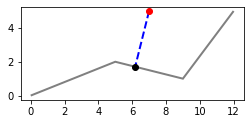

In [ ]:
import matplotlib.pyplot as plt
import shapely
from shapely import Point, LineString
from shapely.ops import nearest_points
from shapely.plotting import plot_points, plot_line

strasse = LineString([(0, 0), (5, 2), (9, 1), (12, 5)])
haus = Point(7, 5)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import shapely
from shapely import Point, LineString
from shapely.ops import nearest_points
from shapely.plotting import plot_points, plot_line

strasse = LineString([(0, 0), (5, 2), (9, 1), (12, 5)])
haus = Point(7, 5)
a, f = nearest_points(haus, strasse)
leitung = LineString([a, f])
print(round(leitung.length, 2))
print(shapely.to_wkt(f, rounding_precision=2))
fig, ax = plt.subplots(figsize=(4, 3))
plot_line(strasse, ax=ax, color='gray', add_points=False)
plot_line(leitung, ax=ax, color='blue', linestyle='--', add_points=False)
plot_points(haus, ax=ax, color='red')
plot_points(f, ax=ax, color='black')
ax.set_aspect('equal')
plt.show()
```

</details>

`LineString([a, f])` erzeugt eine Strecke aus zwei **Punkt-Objekten** (statt aus Tupeln).

In [ ]:
from shapely import Point, LineString

print(LineString([Point(0, 0), Point(3, 4)]).length)

#### Aufgabe 4.5

Gib den Mittelpunkt des Streckenzugs `weg` (halbe Weglänge) gerundet aus und den Punkt nach 3 km (Koordinaten in km).

**Erwartete Ausgabe:**
```
POINT (2 2.5)
POINT (2 1)
```

In [ ]:
import shapely
from shapely import LineString

weg = LineString([(0, 0), (2, 0), (2, 3), (6, 3)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import LineString

weg = LineString([(0, 0), (2, 0), (2, 3), (6, 3)])
print(shapely.to_wkt(weg.interpolate(0.5, normalized=True), rounding_precision=2))
print(shapely.to_wkt(weg.interpolate(3), rounding_precision=2))
```

</details>

#### Aufgabe 4.6

Auf einem Weg sollen alle 2 km Wegweiser stehen, beginnend am Start (0 km) bis höchstens zum Ende. Gib die Positionen gerundet aus.

**Erwartete Ausgabe:**
```
POINT (0 0)
POINT (1.2 1.6)
POINT (2.4 3.2)
POINT (3 5)
POINT (3 7)
POINT (3 9)
```

In [ ]:
import shapely
from shapely import LineString

weg = LineString([(0, 0), (3, 4), (3, 9)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import LineString

weg = LineString([(0, 0), (3, 4), (3, 9)])
d = 0
while d <= weg.length:
    print(shapely.to_wkt(weg.interpolate(d), rounding_precision=2))
    d += 2
```

</details>

#### Aufgabe 4.7

Bei welchem Streckenkilometer (Weglänge vom Start) kommt der Weg den Aussichtspunkten in `punkte` am nächsten? Gib für jeden Namen die Weglänge mit `project()` (2 Stellen) aus.

**Erwartete Ausgabe:**
```
Turm 2.0
See 11.0
Hütte 0.0
```

In [ ]:
from shapely import Point, LineString

weg = LineString([(0, 0), (6, 0), (6, 8)])
punkte = {'Turm': Point(2, 3), 'See': Point(8, 5), 'Hütte': Point(-1, -1)}
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Point, LineString

weg = LineString([(0, 0), (6, 0), (6, 8)])
punkte = {'Turm': Point(2, 3), 'See': Point(8, 5), 'Hütte': Point(-1, -1)}
for name, p in punkte.items():
    print(name, round(weg.project(p), 2))
```

</details>

#### Aufgabe 4.8

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
from shapely import Point, LineString

s = LineString([(0, 0), (10, 0)])
print(Point(3, 4).distance(s))
print(Point(13, 4).distance(s))
print(s.interpolate(0.25, normalized=True))
```

In [ ]:
from shapely import Point, LineString

s = LineString([(0, 0), (10, 0)])
print(Point(3, 4).distance(s))
print(Point(13, 4).distance(s))
print(s.interpolate(0.25, normalized=True))

## 5. Kreis und Gerade

#### Sekante, Tangente, Passante

Ein Kreis mit Mittelpunkt M und Radius r und eine Gerade g:

| Abstand d von M zu g | Lage | gemeinsame Punkte |
|---|---|---|
| d < r | **Sekante** | 2 |
| d = r | **Tangente** | 1 |
| d > r | **Passante** | 0 |

Den Abstand berechnet shapely genau. Beim Vergleich mit r rundet man, weil Kommazahlen kleine Fehler haben.
Die Schnittpunkte mit `M.buffer(r)` sind dagegen nur **Näherungen**, weil der „Kreis“ ein Vieleck ist (siehe Notebook 1). Mit vielen Ecken
(`quad_segs=256`) und Runden auf 2 Stellen stimmen sie aber gut.

In [ ]:
import shapely
from shapely import Point, LineString

m = Point(0, 0)
r = 5
g = LineString([(-10, 3), (10, 3)])
d = m.distance(g)
print(d)
kreis = m.buffer(r, quad_segs=256)
schnitt = kreis.exterior.intersection(g)
print(shapely.to_wkt(schnitt, rounding_precision=2))

#### Aufgabe 5.1

Schreibe eine Funktion `lage(m, r, g)`, die `Sekante`, `Tangente` oder `Passante` zurückgibt (Abstand auf 9 Stellen gerundet vergleichen). Teste mit dem Kreis um (2|1) mit r = 3
und den Geraden in `geraden`.

**Erwartete Ausgabe:**
```
Tangente
Sekante
Passante
Tangente
```

In [ ]:
from shapely import Point, LineString

m = Point(2, 1)
geraden = [LineString([(-10, 4), (10, 4)]), LineString([(-10, 0), (10, 2)]), LineString([(6, -10), (6, 10)]), LineString([(5, -10), (5, 10)])]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Point, LineString

m = Point(2, 1)
geraden = [LineString([(-10, 4), (10, 4)]), LineString([(-10, 0), (10, 2)]), LineString([(6, -10), (6, 10)]), LineString([(5, -10), (5, 10)])]
def lage(m, r, g):
    d = round(m.distance(g), 9)
    if d < r:
        return 'Sekante'
    if d == r:
        return 'Tangente'
    return 'Passante'

for g in geraden:
    print(lage(m, 3, g))
```

</details>

#### Aufgabe 5.2

Gib die Schnittpunkte des Kreises um (0|0) mit r = 5 und der Geraden durch (−10|−5) und (10|5) als sortierte Liste auf 2 Stellen gerundeter Tupel aus (mit `buffer(5, quad_segs=256)`).
Rechne zur Kontrolle selbst nach: Auf der Geraden ist y = x/2, eingesetzt in x² + y² = 25 ergibt x = ±√20.

**Erwartete Ausgabe:**
```
[(-4.47, -2.24), (4.47, 2.24)]
4.47 2.24
```

In [ ]:
from shapely import Point, LineString
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Point, LineString
kreis = Point(0, 0).buffer(5, quad_segs=256)
g = LineString([(-10, -5), (10, 5)])
punkte = []
for p in kreis.exterior.intersection(g).geoms:
    punkte.append((round(p.x, 2), round(p.y, 2)))
print(sorted(punkte))
x = 20 ** 0.5
print(round(x, 2), round(x / 2, 2))
```

</details>

#### Aufgabe 5.3

Ein Leuchtturm (Mittelpunkt (0|0)) ist bis 8 km weit zu sehen. Ein Schiff fährt auf der Strecke von (−12|6) nach (12|−2). Gib aus, ob es den Lichtkreis erreicht, wie nah es
dem Leuchtturm kommt (2 Stellen) und wie viele km seines Weges im Lichtkreis liegen (mit `buffer(8, quad_segs=256)`, 2 Stellen).

**Erwartete Ausgabe:**
```
True
1.9
15.54
```

In [ ]:
from shapely import Point, LineString

turm = Point(0, 0)
schiff = LineString([(-12, 6), (12, -2)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Point, LineString

turm = Point(0, 0)
schiff = LineString([(-12, 6), (12, -2)])
print(turm.distance(schiff) < 8)
print(round(turm.distance(schiff), 2))
licht = turm.buffer(8, quad_segs=256)
print(round(schiff.intersection(licht).length, 2))
```

</details>

#### Aufgabe 5.4

Zeichne den Kreis um (0|0) mit r = 4 (ohne Füllung: `facecolor='none'`, Rand `'C0'`, ohne Eckpunkte) und die drei Geraden y = 2 (`'green'`), y = 4 (`'orange'`), y = 5 (`'red'`) von x = −6 bis 6
(ohne Eckpunkte) und die Schnittpunkte der grünen Geraden mit dem Kreis als schwarze Punkte. Achsen gleich skaliert, Bildgröße 4 × 4.

**Erwartete Ausgabe:**

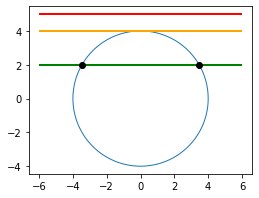

In [ ]:
import matplotlib.pyplot as plt
from shapely import Point, LineString
from shapely.plotting import plot_points, plot_line, plot_polygon
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
from shapely import Point, LineString
from shapely.plotting import plot_points, plot_line, plot_polygon
kreis = Point(0, 0).buffer(4, quad_segs=64)
fig, ax = plt.subplots(figsize=(4, 4))
plot_polygon(kreis, ax=ax, facecolor='none', edgecolor='C0', add_points=False)
for y, farbe in [(2, 'green'), (4, 'orange'), (5, 'red')]:
    plot_line(LineString([(-6, y), (6, y)]), ax=ax, color=farbe, add_points=False)
plot_points(kreis.exterior.intersection(LineString([(-6, 2), (6, 2)])), ax=ax, color='black')
ax.set_aspect('equal')
plt.show()
```

</details>

#### Aufgabe 5.5

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
from shapely import Point, LineString

m = Point(0, 0)
for y in [1, 2, 3]:
    d = m.distance(LineString([(-5, y), (5, y)]))
    if d < 2:
        print(y, 'Sekante')
    elif d == 2:
        print(y, 'Tangente')
    else:
        print(y, 'Passante')
```

In [ ]:
from shapely import Point, LineString

m = Point(0, 0)
for y in [1, 2, 3]:
    d = m.distance(LineString([(-5, y), (5, y)]))
    if d < 2:
        print(y, 'Sekante')
    elif d == 2:
        print(y, 'Tangente')
    else:
        print(y, 'Passante')

## 6. Gemischte Übungen

#### Aufgabe 6.1

Ein Dreieck hat die Ecken A(0|0), B(8|0), C(3|6). Berechne die drei **Höhen**: den Abstand jeder Ecke zur gegenüberliegenden Seite (2 Stellen). Prüfe für jede Höhe,
dass Seite · Höhe / 2 die Fläche ergibt (2 Stellen).

**Erwartete Ausgabe:**
```
6.0 24.0 24.0
6.15 24.0 24.0
7.16 24.0 24.0
```

In [ ]:
from shapely import Point, LineString, Polygon

A, B, C = Point(0, 0), Point(8, 0), Point(3, 6)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Point, LineString, Polygon

A, B, C = Point(0, 0), Point(8, 0), Point(3, 6)
flaeche = Polygon([(0, 0), (8, 0), (3, 6)]).area
for ecke, seite in [(C, LineString([A, B])), (A, LineString([B, C])), (B, LineString([A, C]))]:
    h = ecke.distance(seite)
    print(round(h, 2), round(seite.length * h / 2, 2), flaeche)
```

</details>

#### Aufgabe 6.2

Ein Roboter fährt den Streckenzug `bahn` ab. Hindernisse sind die Vielecke in `hindernisse`. Gib für jedes Hindernis aus, ob die Bahn es trifft (`intersects`), und wenn ja,
wie lang der Teil der Bahn im Hindernis ist (2 Stellen).

**Erwartete Ausgabe:**
```
Kiste 2.0
Tisch frei
Regal 1.0
```

In [ ]:
from shapely import LineString, Polygon

bahn = LineString([(0, 0), (10, 0), (10, 10)])
hindernisse = {'Kiste': Polygon([(3, -1), (5, -1), (5, 1), (3, 1)]), 'Tisch': Polygon([(6, 3), (8, 3), (8, 5), (6, 5)]), 'Regal': Polygon([(9, 6), (12, 6), (12, 7), (9, 7)])}
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import LineString, Polygon

bahn = LineString([(0, 0), (10, 0), (10, 10)])
hindernisse = {'Kiste': Polygon([(3, -1), (5, -1), (5, 1), (3, 1)]), 'Tisch': Polygon([(6, 3), (8, 3), (8, 5), (6, 5)]), 'Regal': Polygon([(9, 6), (12, 6), (12, 7), (9, 7)])}
for name, h in hindernisse.items():
    if bahn.intersects(h):
        print(name, round(bahn.intersection(h).length, 2))
    else:
        print(name, 'frei')
```

</details>

#### Aufgabe 6.3

Sichtlinie: Kann Person A(1|1) Person B(9|7) sehen? Die Sicht ist versperrt, wenn die Strecke AB eine der Wände in `waende` schneidet. Gib `sichtbar` oder die Namen der
störenden Wände aus. Teste auch mit B(9|1).

**Erwartete Ausgabe:**
```
['Wand 2']
['Wand 1']
```

In [ ]:
from shapely import Point, LineString

waende = {'Wand 1': LineString([(4, 0), (4, 3)]), 'Wand 2': LineString([(6, 5), (8, 3)]), 'Wand 3': LineString([(2, 6), (5, 9)])}
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Point, LineString

waende = {'Wand 1': LineString([(4, 0), (4, 3)]), 'Wand 2': LineString([(6, 5), (8, 3)]), 'Wand 3': LineString([(2, 6), (5, 9)])}
for b in [Point(9, 7), Point(9, 1)]:
    sicht = LineString([(1, 1), b])
    stoerend = []
    for name, w in waende.items():
        if sicht.intersects(w):
            stoerend.append(name)
    if stoerend:
        print(stoerend)
    else:
        print('sichtbar')
```

</details>

#### Aufgabe 6.4

Wo kreuzen sich die Seitenhalbierenden des Dreiecks A(0|0), B(6|0), C(2|6)? Erzeuge zwei Seitenhalbierende (Ecke bis Mitte der gegenüberliegenden Seite, Mitte mit `interpolate`)
und gib ihren Schnittpunkt sowie den Schwerpunkt `centroid` des Dreiecks gerundet aus.

**Erwartete Ausgabe:**
```
POINT (2.67 2)
POINT (2.67 2)
```

In [ ]:
import shapely
from shapely import Point, LineString, Polygon

A, B, C = Point(0, 0), Point(6, 0), Point(2, 6)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import Point, LineString, Polygon

A, B, C = Point(0, 0), Point(6, 0), Point(2, 6)
ma = LineString([A, LineString([B, C]).interpolate(0.5, normalized=True)])
mb = LineString([B, LineString([A, C]).interpolate(0.5, normalized=True)])
print(shapely.to_wkt(ma.intersection(mb), rounding_precision=2))
print(shapely.to_wkt(Polygon([A, B, C]).centroid, rounding_precision=2))
```

</details>